# Combined corpora — measurement funnel and reporting specificity

Both-corpora version of `trends.ipynb` §4.2 / `arxiv/trends.ipynb` §4.2: the same
extraction funnel and reporting-specificity trend, S2ORC and arXiv side by side,
computed through the shared `accelscan.webexport` functions so the numbers here can
never drift from the single-corpus notebooks.

**Left:** the funnel for each corpus as a paired horizontal bar per stage — S2ORC
solid, arXiv hatched/translucent — on a shared log x-axis, so the two populations'
relative narrowing is directly comparable stage by stage.

**Right:** the reporting-specificity trend (share of accelerator-using papers naming
a specific model) for both corpora on one axis, one color per corpus.

**Caveat** (inherited from `arxiv/trends.ipynb`): arXiv's raw-LaTeX matching sees
figure captions, spec tables, and comments GROBID drops from S2ORC, biasing
any-mention/candidate prevalence upward; only within-corpus *trends*, not levels,
should be compared.

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from accelscan import webexport as we
from accelscan.config import BUCKET, OUT_PREFIX
from accelscan.paths import analytic_base, get_corpus, s3_uri
from accelscan.plotting import setup_figures
from accelscan.registry import load_registry
from accelscan.s3 import storage_options

# integer year ticks + every figure exported to output/analysis/combined/funnel_specificity/
setup_figures('combined/funnel_specificity')

## Knobs

In [11]:
MODEL_TAG, PROMPT_VERSION = 'qwen3-14b', 'p1'
# Each corpus keeps its own native year window (matches its own trends.ipynb),
# since arXiv's 2026 is real partial-year data and S2ORC's 2026 is an ingestion-lag
# artefact -- reusing one shared window would either truncate arXiv or contaminate
# S2ORC.
YEAR_RANGE = {'s2orc': (2010, 2025), 'arxiv': (2010, 2025)}
CORPUS_LABEL = {'s2orc': 'S2ORC', 'arxiv': 'arXiv'}
CORPUS_COLOR = {'s2orc': '#0072B2', 'arxiv': '#D55E00'}

reg = load_registry(); so = storage_options()

## Load analytic tables (both corpora)

In [12]:
def load_papers(corpus_name):
    c = get_corpus(corpus_name)
    base = s3_uri(analytic_base(c, reg.version, PROMPT_VERSION, MODEL_TAG))
    rd = lambda name: pl.read_parquet(f'{base}/{name}.parquet', storage_options=so)
    year_min, year_max = YEAR_RANGE[corpus_name]
    den = rd('denominator')
    flags = rd('paper_flags')
    papers = (den.join(flags, on=c.key, how='left')
              .with_columns(
                  accel_any=pl.col('accel_any').fill_null(False),
                  accel_used=pl.col('accel_used').fill_null(False),
                  model_specific=pl.col('model_specific').fill_null(False),
                  model_specific_used=pl.col('model_specific_used').fill_null(False),
                  is_candidate=pl.col('is_candidate').fill_null(False))
              .filter(pl.col('year').is_between(year_min, year_max)))
    return papers

papers_by_corpus = {name: load_papers(name) for name in YEAR_RANGE}
for name, papers in papers_by_corpus.items():
    print(f'{CORPUS_LABEL[name]}: {papers.height:,} full-text papers '
          f'{YEAR_RANGE[name][0]}-{YEAR_RANGE[name][1]} | '
          f'{papers["accel_any"].sum():,} with an accelerator mention | '
          f'{papers["accel_used"].sum():,} reporting use')

S2ORC: 11,236,792 full-text papers 2010-2025 | 339,113 with an accelerator mention | 277,304 reporting use
arXiv: 2,126,979 full-text papers 2010-2025 | 231,149 with an accelerator mention | 195,578 reporting use


## Funnel + reporting specificity, both corpora

Same functions as the single-corpus notebooks (`webexport.extraction_funnel`,
`webexport.specificity_share`), called once per corpus.

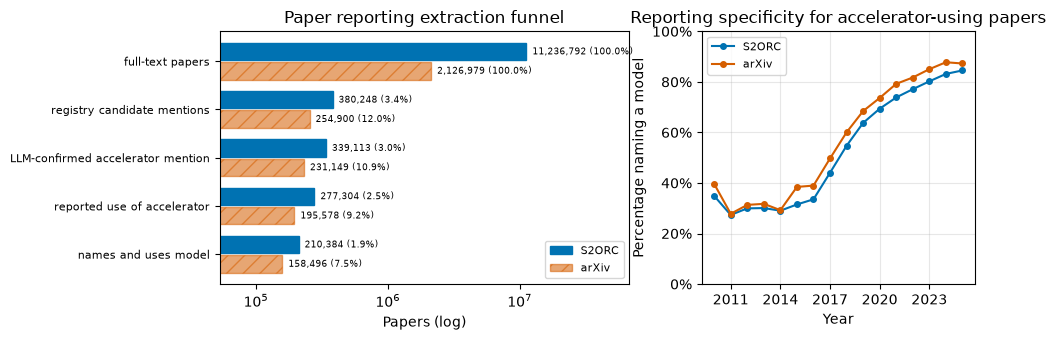

--- S2ORC ---
  11,236,792  100.00%  full-text papers
     380,248    3.38%  registry candidate mentions
     339,113    3.02%  LLM-confirmed accelerator mention
     277,304    2.47%  reported use of accelerator
     210,384    1.87%  names and uses model
shape: (16, 3)
┌──────┬───────┬──────────┐
│ year ┆ n     ┆ specific │
│ ---  ┆ ---   ┆ ---      │
│ i64  ┆ u32   ┆ f64      │
╞══════╪═══════╪══════════╡
│ 2010 ┆ 476   ┆ 0.349    │
│ 2011 ┆ 731   ┆ 0.274    │
│ 2012 ┆ 955   ┆ 0.299    │
│ 2013 ┆ 1184  ┆ 0.301    │
│ 2014 ┆ 1526  ┆ 0.29     │
│ …    ┆ …     ┆ …        │
│ 2021 ┆ 29059 ┆ 0.738    │
│ 2022 ┆ 33258 ┆ 0.771    │
│ 2023 ┆ 42689 ┆ 0.802    │
│ 2024 ┆ 52769 ┆ 0.831    │
│ 2025 ┆ 61282 ┆ 0.845    │
└──────┴───────┴──────────┘
--- arXiv ---
   2,126,979  100.00%  full-text papers
     254,900   11.98%  registry candidate mentions
     231,149   10.87%  LLM-confirmed accelerator mention
     195,578    9.20%  reported use of accelerator
     158,496    7.45%  names and uses m

In [13]:
funnels = {name: we.extraction_funnel(papers)
           for name, papers in papers_by_corpus.items()}
specificity = {name: we.specificity_share(papers, min_papers=50)
              for name, papers in papers_by_corpus.items()}

corpora = list(YEAR_RANGE)   # ['s2orc', 'arxiv'] -- fixes bar/legend order throughout
stages = list(next(iter(funnels.values())))   # same 5 stage labels for both corpora

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), width_ratios=[1.5, 1])

# --- Left: paired funnel bars, one pair per stage, S2ORC solid / arXiv hatched ---
n_corpora = len(corpora)
bar_h = 0.8 / n_corpora
for j, name in enumerate(corpora):
    vals = [funnels[name][s] for s in stages]
    ys = [i + (j - (n_corpora - 1) / 2) * bar_h for i in range(len(stages))]
    axes[0].barh(ys, vals, height=bar_h * 0.9, color=CORPUS_COLOR[name],
                alpha=1.0 if name == 's2orc' else 0.55,
                hatch=None if name == 's2orc' else '//',
                edgecolor=CORPUS_COLOR[name], label=CORPUS_LABEL[name])
    total = vals[0]
    for y, v in zip(ys, vals):
        axes[0].text(v, y, f'  {v:,} ({100 * v / total:.1f}%)', va='center', fontsize=6.5)

axes[0].set_yticks(range(len(stages))); axes[0].set_yticklabels(stages, fontsize=8)
axes[0].set_xscale('log'); axes[0].invert_yaxis()
all_vals = [v for f in funnels.values() for v in f.values()]
axes[0].set_xlim(min(all_vals) / 3, max(all_vals) * 6)
axes[0].set(xlabel='Papers (log)', title='Paper reporting extraction funnel')
axes[0].legend(loc='lower right', fontsize=8)

# --- Right: reporting-specificity trend, both corpora on one axis ---
for name in corpora:
    sp = specificity[name]
    axes[1].plot(sp['year'], 100 * sp['specific'], marker='o', ms=4,
                color=CORPUS_COLOR[name], label=CORPUS_LABEL[name])
axes[1].set(xlabel='Year', ylabel='Percentage naming a model', ylim=(0, 100),
            title='Reporting specificity for accelerator-using papers')
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

for name in corpora:
    print(f'--- {CORPUS_LABEL[name]} ---')
    for k, v in funnels[name].items():
        print(f'{v:12,}  {100 * v / funnels[name]["full-text papers"]:6.2f}%  {k}')
    print(specificity[name].with_columns(pl.col('specific').round(3)))